# 04. Análisis de errores del modelo seleccionado
Se utilizan exclusivamente los resultados producidos por la última ejecución terminada de `03_modelos.ipynb`. El ganador se obtuvo con enero–octubre; aquí se describen sus errores de noviembre, sin entrenar, cambiar parámetros ni ajustar el umbral.


## 1. Recuperación de predicciones nuevas
El índice de resultados identifica la carpeta generada por el notebook 03. Si no existe, es necesario ejecutar primero ese notebook; no se sustituyen los resultados por archivos antiguos.


In [1]:
import sys
from pathlib import Path
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / 'src'))
sns.set_theme(style='whitegrid')

from sklearn.metrics import confusion_matrix
from metricas import calcular_metricas
base = raiz / 'outputs' / 'entrega_actual'
indice = base / 'ultima_ejecucion.json'
if not indice.exists():
    raise FileNotFoundError('Faltan los resultados actuales. Ejecute primero 03_modelos.ipynb.')
ejecucion = json.loads(indice.read_text(encoding='utf-8'))['ejecucion']
carpeta = base / ejecucion
protocolo = json.loads((carpeta / 'protocolo.json').read_text(encoding='utf-8'))
predicciones = pd.read_csv(carpeta / 'predicciones_noviembre.csv', float_precision='round_trip')
guardadas = pd.read_csv(carpeta / 'metricas_noviembre.csv', float_precision='round_trip')
ganador, umbral = protocolo['modelo_seleccionado'], protocolo['umbral']
nombre_modelo = protocolo['nombre_modelo']
assert protocolo['ejecucion'] == ejecucion
assert predicciones['month'].eq(11).all() and predicciones['id_vuelo'].is_unique
assert len(predicciones) == protocolo['n_noviembre']
print('Ejecución analizada:', ejecucion, '| modelo:', nombre_modelo)


Ejecución analizada: 20261027T151138_544528Z | modelo: HistGradientBoosting


## 2. Métricas y matriz de confusión
Precision es la proporción de alertas correctas; recall, la proporción de retrasos detectados. F1 combina ambas. Las métricas se calculan nuevamente con las probabilidades recién guardadas y se contrastan con la tabla del 03.


,HistGradientBoosting
accuracy,0.779986
precision,0.372701
recall,0.315444
f1,0.341691
roc_auc,0.668367
average_precision,0.344786


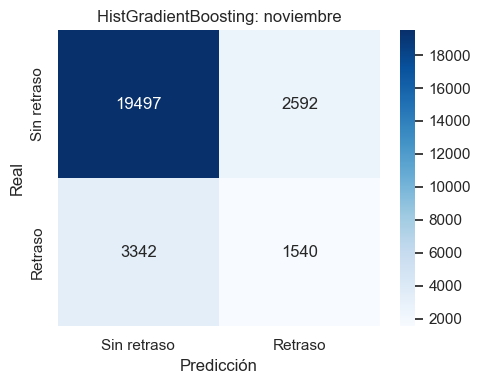

In [2]:
p = predicciones['prob_' + ganador].to_numpy()
pred = (p >= umbral).astype(int)
assert np.array_equal(pred, predicciones['pred_' + ganador])
metricas = calcular_metricas(predicciones['y_real'], p, umbral=umbral)
referencia = guardadas.set_index('id').loc[ganador]
for metrica, valor in metricas.items():
    assert abs(valor - referencia[metrica]) < 1e-12
display(pd.Series(metricas, name=nombre_modelo).round(6).to_frame())
cm = confusion_matrix(predicciones['y_real'], pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Sin retraso', 'Retraso'], yticklabels=['Sin retraso', 'Retraso'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title(nombre_modelo + ': noviembre')
plt.tight_layout()
plt.show()


In [3]:
errores = predicciones[['id_vuelo', 'year', 'month', 'day', 'origin', 'hour', 'y_real']].copy()
errores['pred'] = pred
errores['TP'] = ((errores['y_real'] == 1) & (pred == 1)).astype(int)
errores['FN'] = ((errores['y_real'] == 1) & (pred == 0)).astype(int)
errores['FP'] = ((errores['y_real'] == 0) & (pred == 1)).astype(int)
errores['TN'] = ((errores['y_real'] == 0) & (pred == 0)).astype(int)
totales = errores[['TN', 'FP', 'FN', 'TP']].sum()
assert totales.sum() == len(errores)
display(totales.rename('vuelos').to_frame())
display(Markdown(f"Se detectan {totales['TP']:,} retrasos y quedan {totales['FN']:,} sin detectar. "
    f"Hay {totales['FP']:,} alertas incorrectas y {totales['TN']:,} negativos correctamente clasificados."))


,vuelos
TN,19497
FP,2592
FN,3342
TP,1540


Se detectan 1,540 retrasos y quedan 3,342 sin detectar. Hay 2,592 alertas incorrectas y 19,497 negativos correctamente clasificados.

Un falso positivo es una alerta en un vuelo sin retraso observado. Un falso negativo es un retraso que no generó alerta. Sus consecuencias operativas pueden ser distintas; este análisis no fija costos ni optimiza decisiones con noviembre.

## 3. Errores por aeropuerto, día y franja horaria
Se muestran cantidades y tasas para distinguir tamaño del grupo y riesgo condicionado. FNR = FN / positivos; FPR = FP / negativos. Los grupos con menos de 200 vuelos, 30 positivos o 30 negativos requieren especial cautela.


In [4]:
nombres_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
dia = pd.to_datetime(errores[['year', 'month', 'day']]).dt.dayofweek
errores['dia_semana'] = pd.Categorical(dia.map(dict(enumerate(nombres_dias))),
                                     categories=nombres_dias, ordered=True)
errores['franja'] = pd.cut(errores['hour'], bins=[-1, 5, 11, 17, 23],
                         labels=['00–05', '06–11', '12–17', '18–23'])

def resumir_segmento(columna):
    tabla = errores.groupby(columna, observed=True)[['TP', 'FN', 'FP', 'TN']].sum()
    tabla['n'] = tabla[['TP', 'FN', 'FP', 'TN']].sum(axis=1)
    tabla['positivos'] = tabla['TP'] + tabla['FN']
    tabla['negativos'] = tabla['TN'] + tabla['FP']
    tabla['fnr_pct'] = 100 * tabla['FN'] / tabla['positivos'].replace(0, np.nan)
    tabla['fpr_pct'] = 100 * tabla['FP'] / tabla['negativos'].replace(0, np.nan)
    tabla['soporte_suficiente'] = (tabla['n'] >= 200) & (tabla['positivos'] >= 30) & (tabla['negativos'] >= 30)
    assert tabla['n'].sum() == len(errores)
    return tabla


,n,positivos,negativos,FN,FP,fnr_pct,fpr_pct,soporte_suficiente
origin,,,,,,,,
EWR,9603,1677,7926,1074,1117,64.04,14.09,True
JFK,8645,1417,7228,1049,685,74.03,9.48,True
LGA,8723,1788,6935,1219,790,68.18,11.39,True


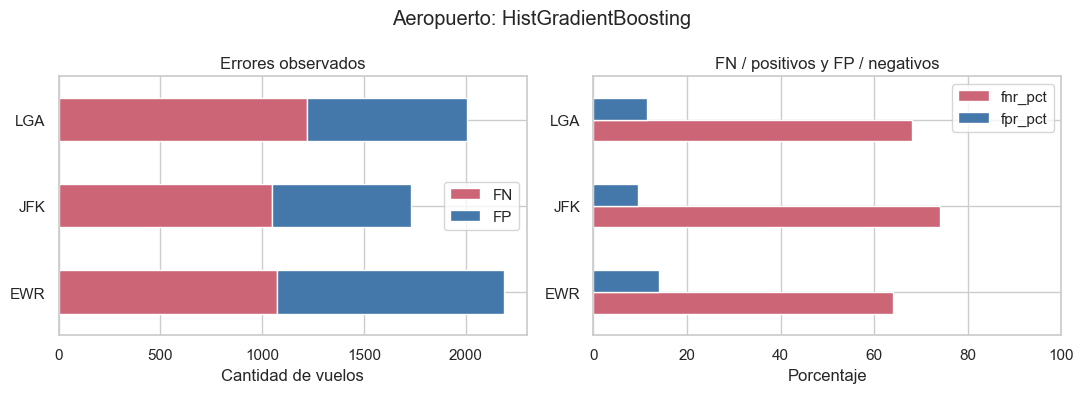

,n,positivos,negativos,FN,FP,fnr_pct,fpr_pct,soporte_suficiente
dia_semana,,,,,,,,
Lunes,3847,613,3234,478,518,77.98,16.02,True
Martes,3874,795,3079,682,211,85.79,6.85,True
Miércoles,3888,783,3105,417,388,53.26,12.50,True
Jueves,3574,656,2918,361,472,55.03,16.18,True
Viernes,4548,855,3693,458,761,53.57,20.61,True
Sábado,3695,401,3294,389,49,97.01,1.49,True
Domingo,3545,779,2766,557,193,71.50,6.98,True


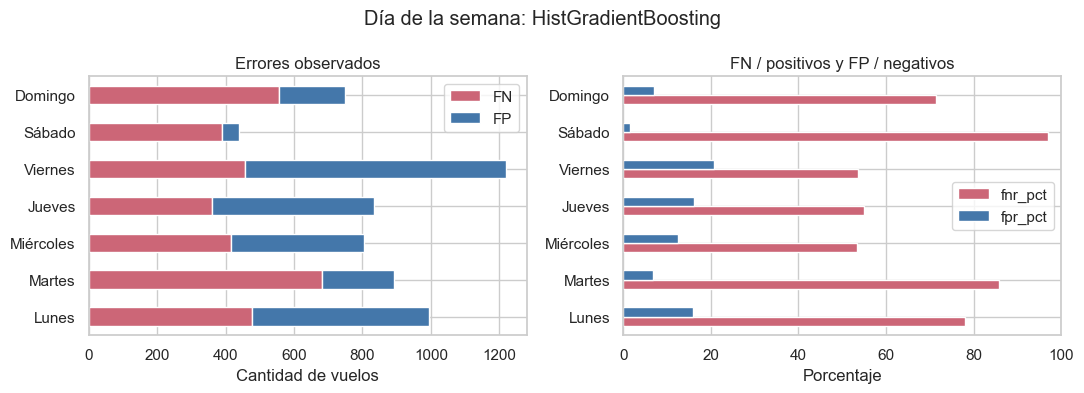

,n,positivos,negativos,FN,FP,fnr_pct,fpr_pct,soporte_suficiente
franja,,,,,,,,
00–05,120,5,115,5,0,100.00,0.00,False
06–11,10413,1313,9100,1185,302,90.25,3.32,True
12–17,10502,2002,8500,1321,1363,65.98,16.04,True
18–23,5936,1562,4374,831,927,53.20,21.19,True


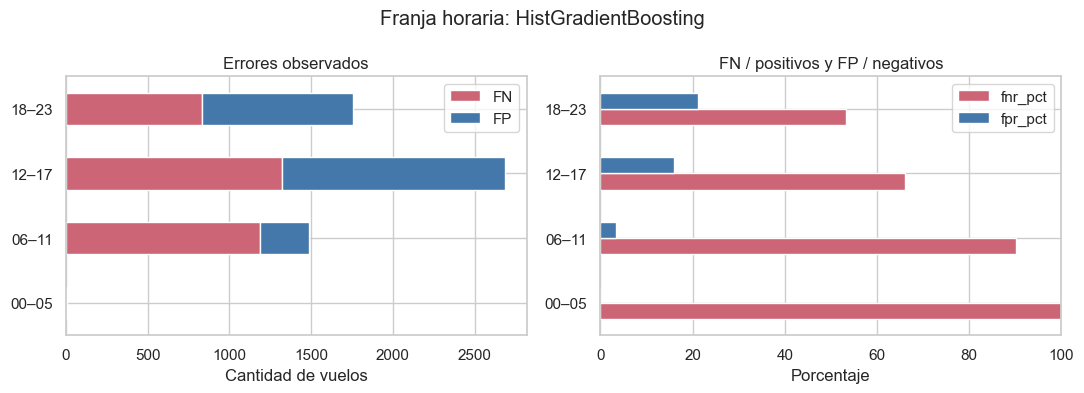

In [5]:
resumenes = {}
for columna, titulo in [('origin', 'Aeropuerto'), ('dia_semana', 'Día de la semana'), ('franja', 'Franja horaria')]:
    tabla = resumir_segmento(columna)
    resumenes[columna] = tabla
    display(tabla[['n', 'positivos', 'negativos', 'FN', 'FP', 'fnr_pct', 'fpr_pct', 'soporte_suficiente']].round(2))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    tabla[['FN', 'FP']].plot.barh(stacked=True, ax=axes[0], color=['#CC6677', '#4477AA'])
    axes[0].set(xlabel='Cantidad de vuelos', ylabel='', title='Errores observados')
    tabla[['fnr_pct', 'fpr_pct']].plot.barh(ax=axes[1], color=['#CC6677', '#4477AA'])
    axes[1].set(xlabel='Porcentaje', ylabel='', title='FN / positivos y FP / negativos', xlim=(0, 100))
    fig.suptitle(titulo + ': ' + nombre_modelo)
    plt.tight_layout()
    plt.show()


Un grupo puede reunir más errores por tener más vuelos y no por una tasa mayor. Los porcentajes tienen denominadores distintos; las diferencias no demuestran causalidad.

## 4. Resultados y conclusiones
El modelo y el umbral permanecen fijados por el protocolo del 03. Las conclusiones se calculan con esta ejecución y no sustituyen al ganador a partir de noviembre.


In [6]:
aeropuertos = resumenes['origin']
origen_fn = aeropuertos['FN'].idxmax()
origen_fnr = aeropuertos['fnr_pct'].idxmax()
display(Markdown(f"**Modelo:** {nombre_modelo}. F1 de noviembre: {metricas['f1']:.4f}; "
    f"recall: {metricas['recall']:.4f}. **Segmentos:** {origen_fn} concentra "
    f"{int(aeropuertos.loc[origen_fn, 'FN'])} falsos negativos; la mayor FNR por aeropuerto "
    f"corresponde a {origen_fnr} ({aeropuertos.loc[origen_fnr, 'fnr_pct']:.2f}%). "
    "Son diferencias descriptivas, sin una causa demostrada."))
analisis = carpeta / 'analisis_errores'
analisis.mkdir(exist_ok=True)
pd.Series(metricas, name='valor').to_csv(analisis / 'metricas_seleccionado.csv')
pd.DataFrame(cm, index=['real_0', 'real_1'], columns=['pred_0', 'pred_1']).to_csv(analisis / 'matriz_confusion.csv')
for columna, tabla in resumenes.items():
    tabla.to_csv(analisis / ('errores_por_' + columna + '.csv'))
print('Tablas del análisis:', analisis.relative_to(raiz))


**Modelo:** HistGradientBoosting. F1 de noviembre: 0.3417; recall: 0.3154. **Segmentos:** LGA concentra 1219 falsos negativos; la mayor FNR por aeropuerto corresponde a JFK (74.03%). Son diferencias descriptivas, sin una causa demostrada.

Tablas del análisis: outputs\entrega_actual\20261027T151138_544528Z\analisis_errores


## 5. Limitaciones y trabajo futuro
- Se reproduce el rendimiento de un modelo seleccionado en desarrollo; no se demuestra utilidad operativa ni causalidad.
- El clima tiene disponibilidad estimada y los horarios no cuentan con versiones históricas verificadas.
- Los atributos de aeronaves se excluyeron por calidad y disponibilidad cuestionables.
- Las etiquetas desconocidas pueden introducir sesgo; no todos esos vuelos son cancelaciones.
- Noviembre ya fue consultado y puede haber influido en decisiones previas. La exposición del test de diciembre limita su independencia; aquí no se utiliza.
- Un año de vuelos de NYC no demuestra generalización a otros años o aeropuertos. Las probabilidades no deben asumirse calibradas.

La línea base permite reconocer el efecto del desbalance; las familias aprendidas se comparan con el mismo protocolo. Persisten errores de ambos tipos. El trabajo futuro puede estudiar más años, disponibilidad real y costos de las alertas dentro del desarrollo, sin ajustar retrospectivamente con noviembre.
